# ASCENT 4-130, Module 1 : Solutions IA pour la prise de décision

**Formation** : Les agents autonomes et aide à la décision (Jour 1, module 1, 2 heures).

**Objectifs du module**

- Explorer trois familles de solutions : systèmes à règles, réseaux bayésiens, apprentissage supervisé.
- Analyser les avantages et les limites de chacune sur un même problème.
- Étudier deux cas du syllabus : le diagnostic médical et les systèmes de recommandation.

**Fil rouge** : un robot autonome circule dans un entrepôt logistique. À chaque instant, son superviseur de bord doit choisir entre `CONTINUER`, `RALENTIR`, `ARRET` et `MAINTENANCE` à partir de six mesures (batterie, température moteur, vibration, distance à l'obstacle, charge, stabilité du lidar).

**Travaux pratiques du syllabus** : identifier et comparer des solutions IA adaptées à un problème donné.

| Partie | Contenu | Durée indicative |
|---|---|---|
| 1 | Le problème et les données | 10 min |
| 2 | Système à règles | 15 min |
| 3 | Réseau bayésien | 20 min |
| 4 | Apprentissage supervisé | 15 min |
| 5 | Comparaison des trois approches | 15 min |
| 6 | Étude de cas : diagnostic médical | 10 min |
| 7 | Étude de cas : recommandation | 15 min |

Toutes les données sont synthétiques. Le notebook est livré exécuté : les sorties visibles servent de résultats de repli si l'exécution n'est pas possible en salle.

In [1]:
# Installation automatique (Colab ou poste sans le paquet). Sans effet si tout est déjà installé.
import importlib.util, subprocess, sys
if importlib.util.find_spec("ascent_agents") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ascent-agents[complet] @ https://martinobettucci.github.io/4-120/dist/ascent_agents-1.0.0-py3-none-any.whl"])

In [2]:
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

from ascent_agents import detecter_appareil, fixer_graines
from ascent_agents.decision import (
    DECISIONS, NOMS_VARIABLES, SEUILS, VARIABLES,
    DecideurBayesien, ReseauBayesien, exactitude, generer_diagnostic_medical,
    generer_etats_robot, generer_notes, matrice_confusion, reseau_panne,
    valeur_predictive_positive, vers_entree,
)
from ascent_agents.visualisation import BLEU, GRIS, JAUNE, NOIR, ROUGE, VERT, style

APPAREIL = detecter_appareil()
fixer_graines(4130)
style()
COULEURS_DECISION = {"CONTINUER": VERT, "RALENTIR": JAUNE, "ARRET": ROUGE, "MAINTENANCE": BLEU}

Aucun GPU CUDA detecte : repli sur CPU (tous les notebooks restent executables).
PyTorch 2.15.0+cpu


## 1. Le problème et les données

Le générateur produit des états du robot avec des **variables cachées** (usure mécanique, capteur encrassé, panne imminente) que les approches ne voient pas. La décision de référence est celle d'un expert qui connaîtrait ces variables cachées. Une petite part des étiquettes est tirée au hasard : aucune approche ne peut atteindre 100 %.

In [3]:
PARAMETRES = {
    "n_etats": 3000,         # taille du jeu de données
    "graine": 4130,          # changer la graine change le tirage
    "part_test": 0.3,        # part réservée à l'évaluation
}

donnees = generer_etats_robot(PARAMETRES["n_etats"], PARAMETRES["graine"])
X, y = donnees["X"], donnees["y"]
n_test = int(PARAMETRES["part_test"] * len(X))
X_app, y_app, X_test, y_test = X[:-n_test], y[:-n_test], X[-n_test:], y[-n_test:]

table = pd.DataFrame(X.astype(float), columns=NOMS_VARIABLES).round(2)
table["decision"] = [DECISIONS[i] for i in y]
print(f"{len(X_app)} états d'apprentissage, {len(X_test)} états de test")
table.head(8)

2100 états d'apprentissage, 900 états de test


,batterie,temperature,vibration,distance_obstacle,charge,bruit_capteur,decision
0,34.58,100.53,6.09,0.61,91.98,0.05,ARRET
1,9.84,64.46,2.36,2.12,17.43,0.08,RALENTIR
2,28.26,58.58,1.01,1.14,79.62,0.06,RALENTIR
3,39.36,69.98,1.28,3.35,68.47,0.12,MAINTENANCE
4,11.17,61.77,2.41,4.92,81.63,0.25,RALENTIR
5,45.29,64.64,1.30,1.43,82.52,0.13,RALENTIR
6,26.02,81.36,3.12,4.23,0.45,0.07,MAINTENANCE
7,60.75,55.57,1.49,0.94,30.79,0.19,RALENTIR


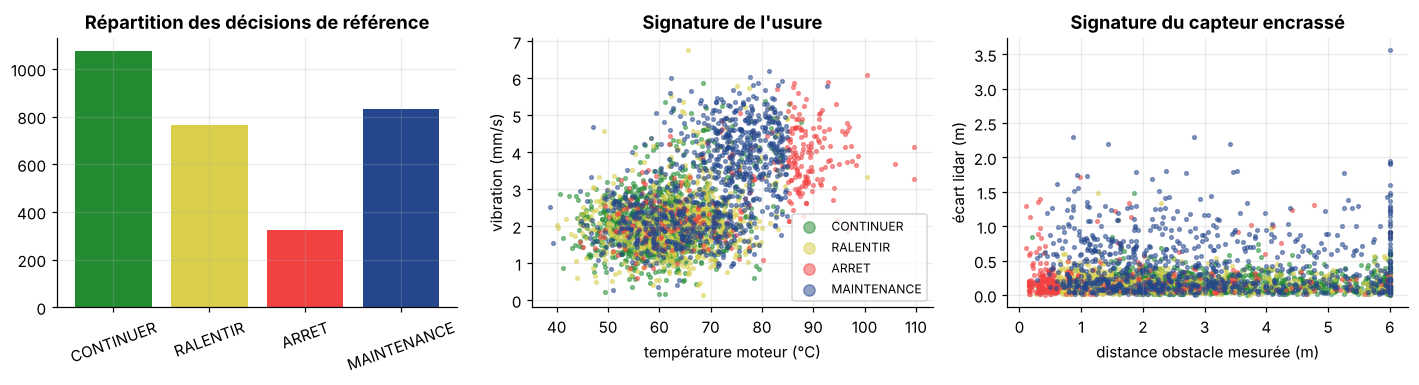

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
effectifs = pd.Series(table["decision"]).value_counts().reindex(DECISIONS)
axes[0].bar(DECISIONS, effectifs, color=[COULEURS_DECISION[d] for d in DECISIONS])
axes[0].set_title("Répartition des décisions de référence")
axes[0].tick_params(axis="x", labelrotation=20)
for d in DECISIONS:
    masque = table["decision"] == d
    axes[1].scatter(table.loc[masque, "temperature"], table.loc[masque, "vibration"], s=6, alpha=0.5, color=COULEURS_DECISION[d], label=d)
    axes[2].scatter(table.loc[masque, "distance_obstacle"], table.loc[masque, "bruit_capteur"], s=6, alpha=0.5, color=COULEURS_DECISION[d])
axes[1].set(xlabel="température moteur (°C)", ylabel="vibration (mm/s)", title="Signature de l'usure")
axes[2].set(xlabel="distance obstacle mesurée (m)", ylabel="écart lidar (m)", title="Signature du capteur encrassé")
axes[1].legend(markerscale=3, fontsize=8)
plt.tight_layout()

**Lecture.** Les classes se chevauchent : une vibration forte suggère l'usure mais ne la prouve pas. C'est cette incertitude qui distingue les trois approches.

## 2. Système à règles

Un système à règles encode le savoir d'un expert sous la forme « si condition alors décision ». Les règles sont ordonnées : la première qui se déclenche l'emporte. La décision est immédiatement explicable, puisqu'il suffit de citer la règle.

In [5]:
# Chaque règle : (identifiant, description lisible, condition, décision). L'ordre fixe la priorité.
REGLES = [
    ("R1", "distance obstacle < 0,6 m", lambda e: e["distance_obstacle"] < 0.6, "ARRET"),
    ("R2", "température > 85 °C", lambda e: e["temperature"] > 85, "ARRET"),
    ("R3", "vibration > 3,5 mm/s et température > 70 °C", lambda e: e["vibration"] > 3.5 and e["temperature"] > 70, "MAINTENANCE"),
    ("R4", "écart lidar > 0,5 m", lambda e: e["bruit_capteur"] > 0.5, "MAINTENANCE"),
    ("R5", "batterie < 20 %", lambda e: e["batterie"] < 20, "RALENTIR"),
    ("R6", "distance obstacle < 1,5 m", lambda e: e["distance_obstacle"] < 1.5, "RALENTIR"),
    ("R7", "charge > 80 kg et température > 65 °C", lambda e: e["charge"] > 80 and e["temperature"] > 65, "RALENTIR"),
]


def decider_regles(entree, regles=REGLES, defaut="CONTINUER"):
    """Retourne (décision, identifiants des règles déclenchées)."""
    declenchees = [(ident, decision) for ident, _, condition, decision in regles if condition(entree)]
    if not declenchees:
        return defaut, []
    return declenchees[0][1], [ident for ident, _ in declenchees]


def predire_regles(X, regles=REGLES):
    return np.array([DECISIONS.index(decider_regles(vers_entree(x), regles)[0]) for x in X])


# Un état à modifier librement pour observer la décision et son explication.
ETAT = {"batterie": 64, "temperature": 74, "vibration": 4.1, "distance_obstacle": 1.2, "charge": 35, "bruit_capteur": 0.12}
decision, ids = decider_regles(ETAT)
print("Décision :", decision, "| règles déclenchées :", ids)

Décision : MAINTENANCE | règles déclenchées : ['R3', 'R6']


Exactitude des règles sur le jeu de test : 85.3%


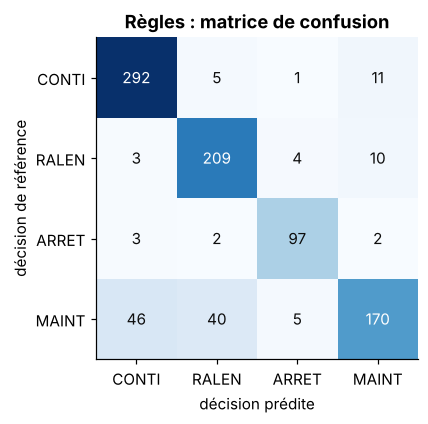

In [6]:
pred_regles = predire_regles(X_test)
print(f"Exactitude des règles sur le jeu de test : {exactitude(y_test, pred_regles):.1%}")


def tracer_confusion(y_vrai, y_predit, titre, ax=None):
    m = matrice_confusion(y_vrai, y_predit)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 3.8))
    ax.imshow(m, cmap="Blues")
    ax.grid(False)
    ax.set_xticks(range(4), [d[:5] for d in DECISIONS])
    ax.set_yticks(range(4), [d[:5] for d in DECISIONS])
    ax.set(xlabel="décision prédite", ylabel="décision de référence", title=titre)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, m[i, j], ha="center", va="center", color="white" if m[i, j] > m.max() / 2 else NOIR)
    return ax


tracer_confusion(y_test, pred_regles, "Règles : matrice de confusion");

**Lecture.** Les erreurs se concentrent sur `MAINTENANCE` : les règles à seuils nets ratent les pannes dont les symptômes restent juste sous les seuils, et l'usure sans surchauffe passe inaperçue.

### Exercice 1 : améliorer le jeu de règles

Ajoutez ou modifiez une règle pour mieux détecter les besoins de maintenance, puis mesurez l'effet sur l'exactitude, sur le rappel de la classe `MAINTENANCE` (part des besoins réels détectés) et sur la matrice de confusion. Pistes : une vibration très forte, seule, est déjà un signal, et le graphique de droite de la partie 1 montre où se situent les capteurs encrassés. Attention à la position de la règle dans la liste, qui fixe sa priorité.

In [7]:
# À COMPLÉTER : la liste ci-dessous est une copie des règles d'origine. Insérez votre règle.
mes_regles = list(REGLES)
# mes_regles.insert(3, ("R8", "...", lambda e: ..., "MAINTENANCE"))

pred_mes_regles = predire_regles(X_test, mes_regles)
print(f"Exactitude avec vos règles : {exactitude(y_test, pred_mes_regles):.1%}")
print(f"Rappel MAINTENANCE         : {np.mean(pred_mes_regles[y_test == 3] == 3):.1%}")

Exactitude avec vos règles : 85.3%
Rappel MAINTENANCE         : 65.1%


Avec R9 (vibration seule) : exactitude 83.0%, rappel MAINTENANCE 71.6%
Exactitude d'origine : 85.3%, avec R8 : 86.4%
Rappel MAINTENANCE d'origine : 65.1%, avec R8 : 72.8%


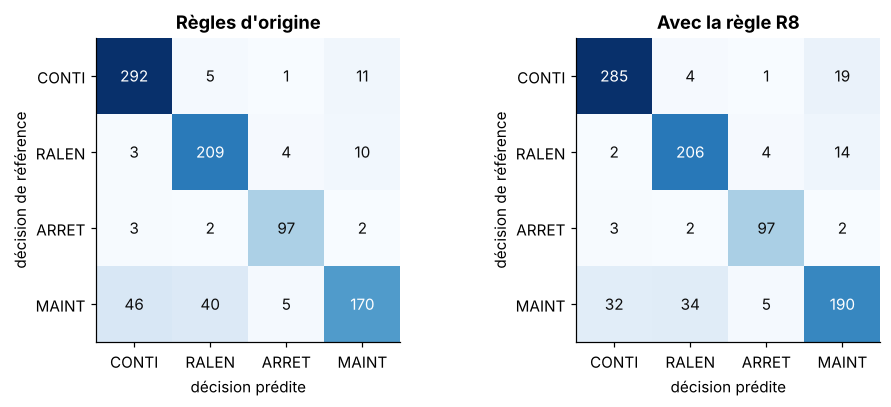

In [8]:
# Solution possible : abaisser le seuil d'instabilité du lidar (0,4 m au lieu de 0,5 m).
regles_v2 = list(REGLES)
regles_v2.insert(3, ("R8", "écart lidar > 0,4 m", lambda e: e["bruit_capteur"] > 0.4, "MAINTENANCE"))
pred_v2 = predire_regles(X_test, regles_v2)
# Contre-exemple instructif : la vibration seule détecte plus de pannes mais crée trop de fausses alertes.
regles_v3 = list(REGLES)
regles_v3.insert(3, ("R9", "vibration > 3,0 mm/s", lambda e: e["vibration"] > 3.0, "MAINTENANCE"))
pred_v3 = predire_regles(X_test, regles_v3)
print(f"Avec R9 (vibration seule) : exactitude {exactitude(y_test, pred_v3):.1%}, rappel MAINTENANCE {np.mean(pred_v3[y_test == 3] == 3):.1%}")
print(f"Exactitude d'origine : {exactitude(y_test, pred_regles):.1%}, avec R8 : {exactitude(y_test, pred_v2):.1%}")
print(f"Rappel MAINTENANCE d'origine : {np.mean(pred_regles[y_test == 3] == 3):.1%}, avec R8 : {np.mean(pred_v2[y_test == 3] == 3):.1%}")
# R8 améliore les deux mesures. R9 augmente le rappel mais fait baisser l'exactitude : l'exactitude
# globale ne suffit pas à juger une règle, il faut regarder la classe qui compte pour le métier.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
tracer_confusion(y_test, pred_regles, "Règles d'origine", axes[0])
tracer_confusion(y_test, pred_v2, "Avec la règle R8", axes[1])
plt.tight_layout()

## 3. Réseau bayésien

Un réseau bayésien représente les **relations de cause à effet** entre variables, avec une probabilité conditionnelle par nœud. Il répond à la question que les règles éludent : sachant ce que j'observe, quelle est la probabilité de chaque cause cachée ?

### 3.1 Un réseau minimal, calculé à la main

Trois nœuds : `usure` → `vibration_forte` et `usure` → `panne`. L'inférence par énumération applique la définition : P(panne | vibration) = P(panne, vibration) / P(vibration), chaque terme étant une somme sur les valeurs de la variable cachée `usure`.

In [9]:
P_USURE = 0.25
P_VIBRATION = {True: 0.62, False: 0.01}   # P(vibration forte | usure)
P_PANNE = {True: 0.65, False: 0.03}       # P(panne | usure)


def jointe(usure, vibration, panne):
    """P(usure, vibration, panne) = P(usure) × P(vibration | usure) × P(panne | usure)."""
    p = P_USURE if usure else 1 - P_USURE
    p *= P_VIBRATION[usure] if vibration else 1 - P_VIBRATION[usure]
    p *= P_PANNE[usure] if panne else 1 - P_PANNE[usure]
    return p


numerateur = sum(jointe(u, True, True) for u in (True, False))
denominateur = sum(jointe(u, True, p) for u in (True, False) for p in (True, False))
a_priori = sum(jointe(u, v, True) for u in (True, False) for v in (True, False))
print(f"P(panne) sans observation       : {a_priori:.3f}")
print(f"P(panne | vibration forte)      : {numerateur / denominateur:.3f}")

P(panne) sans observation       : 0.185
P(panne | vibration forte)      : 0.621


Observer une vibration forte multiplie la probabilité de panne par plus de trois, alors que la vibration ne cause pas la panne : l'information remonte vers la cause commune (l'usure) puis redescend.

### 3.2 Le réseau complet du robot

La classe `ReseauBayesien` du paquet généralise ce calcul à un nombre quelconque de nœuds. L'énumération reste exacte, mais son coût double à chaque variable cachée ajoutée : elle convient aux petits réseaux. Ce calcul est séquentiel, le GPU n'y apporte rien.

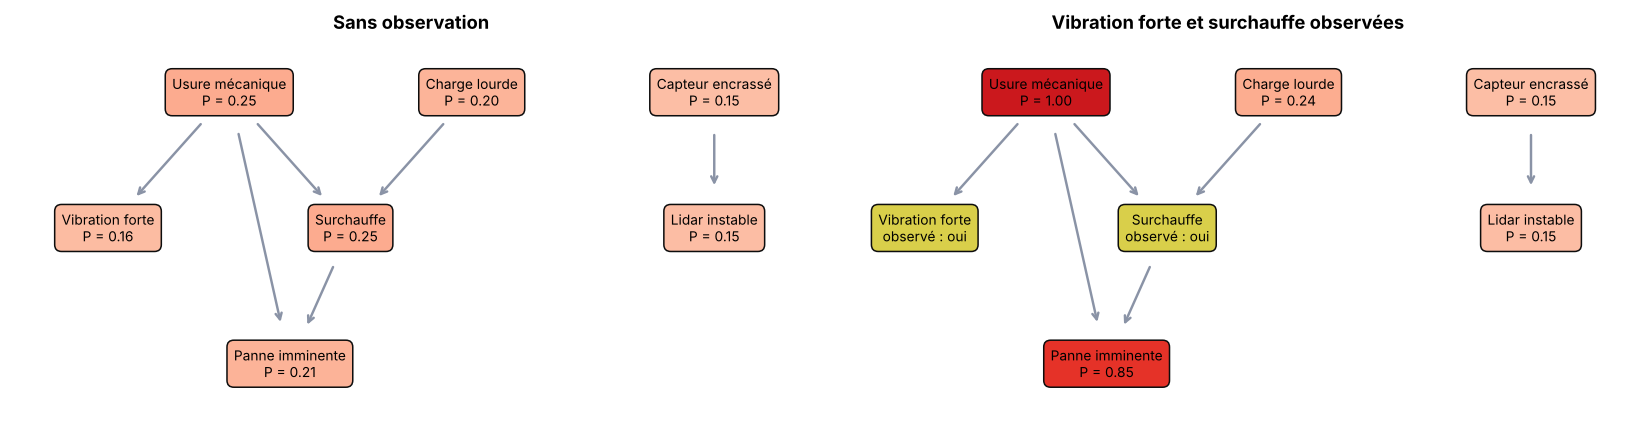

In [10]:
reseau = reseau_panne()
POSITIONS = {
    "usure": (1, 2), "charge_lourde": (3, 2), "encrasse": (5, 2),
    "vibration_forte": (0, 1), "surchauffe": (2, 1), "bruit_capteur": (5, 1), "panne": (1.5, 0),
}


def tracer_reseau(reseau, evidences=None, ax=None):
    """Dessine le réseau. Nœuds observés en jaune, probabilité a posteriori affichée pour les autres."""
    evidences = evidences or {}
    if ax is None:
        _, ax = plt.subplots(figsize=(8.5, 4))
    ax.axis("off")
    for parent, enfant in reseau.arcs():
        ax.annotate("", POSITIONS[enfant], POSITIONS[parent], arrowprops=dict(arrowstyle="->", color=GRIS, lw=1.6, shrinkA=28, shrinkB=28))
    for nom, (x, yy) in POSITIONS.items():
        if nom in evidences:
            texte, couleur = f"{reseau.noeuds[nom]['libelle']}\nobservé : {'oui' if evidences[nom] else 'non'}", JAUNE
        else:
            p = reseau.posterieur(nom, evidences)[True]
            texte, couleur = f"{reseau.noeuds[nom]['libelle']}\nP = {p:.2f}", plt.cm.Reds(0.15 + 0.6 * p)
        ax.text(x, yy, texte, ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round,pad=0.5", fc=couleur, ec=NOIR))
    ax.set(xlim=(-0.8, 5.8), ylim=(-0.4, 2.4))
    return ax


fig, axes = plt.subplots(1, 2, figsize=(15, 4))
tracer_reseau(reseau, {}, axes[0]).set_title("Sans observation")
tracer_reseau(reseau, {"vibration_forte": True, "surchauffe": True}, axes[1]).set_title("Vibration forte et surchauffe observées")
plt.tight_layout()

In [11]:
# L'effet d'explication : une charge lourde explique la surchauffe, donc l'usure devient moins probable.
EVIDENCES = {"surchauffe": True}             # à modifier : ajouter "charge_lourde": True, "vibration_forte": False...
for ev in (EVIDENCES, {**EVIDENCES, "charge_lourde": True}, {**EVIDENCES, "charge_lourde": True, "vibration_forte": True}):
    print(f"{str(ev):75s} P(usure) = {reseau.posterieur('usure', ev)[True]:.2f}   P(panne) = {reseau.posterieur('panne', ev)[True]:.2f}")

{'surchauffe': True}                                                        P(usure) = 0.77   P(panne) = 0.69
{'surchauffe': True, 'charge_lourde': True}                                 P(usure) = 0.58   P(panne) = 0.57
{'surchauffe': True, 'charge_lourde': True, 'vibration_forte': True}        P(usure) = 0.99   P(panne) = 0.84


### 3.3 Des probabilités à la décision

Le réseau fournit des probabilités, pas une décision. Une politique à seuils fait le lien : maintenance si P(panne) ou P(capteur encrassé) dépasse un seuil, prudence au delà d'un seuil plus bas. Les mesures continues sont d'abord discrétisées (par exemple vibration forte si elle dépasse 3,5 mm/s).

État : {'batterie': 64, 'temperature': 74, 'vibration': 4.1, 'distance_obstacle': 1.2, 'charge': 35, 'bruit_capteur': 0.12}
Décision bayésienne : MAINTENANCE | probabilités des causes cachées : {'panne': 0.85, 'encrasse': 0.04, 'usure': 1.0}
Exactitude sur le jeu de test : 80.2%


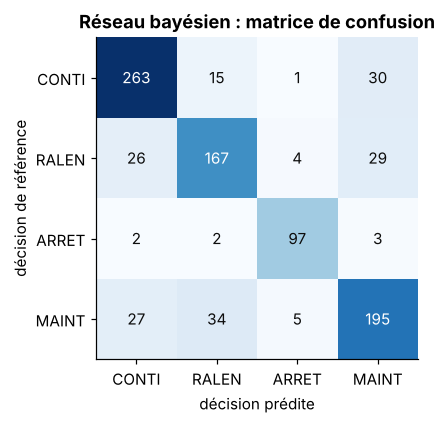

In [12]:
PARAMETRES_BAYES = {
    "seuil_maintenance": 0.5,   # P(panne) ou P(encrassé) au delà : MAINTENANCE
    "seuil_prudence": 0.25,     # P(panne) au delà : RALENTIR
}
bayes = DecideurBayesien(reseau, **PARAMETRES_BAYES)
decision, post = bayes.decider(ETAT)
print("État :", ETAT)
print("Décision bayésienne :", decision, "| probabilités des causes cachées :", {k: round(v, 2) for k, v in post.items()})
pred_bayes = bayes.predire(X_test)
print(f"Exactitude sur le jeu de test : {exactitude(y_test, pred_bayes):.1%}")
tracer_confusion(y_test, pred_bayes, "Réseau bayésien : matrice de confusion");

### Exercice 2 : régler le compromis de la maintenance

Envoyer un robot sain en maintenance coûte du temps, laisser rouler un robot en panne coûte plus cher. Faites varier `seuil_maintenance` entre 0,1 et 0,9 et tracez, pour la classe `MAINTENANCE`, le rappel (part des besoins réels détectés) et la précision (part des alertes justifiées). Quel seuil choisir si une panne manquée coûte cinq fois plus qu'une fausse alerte ?

In [13]:
# À COMPLÉTER : calculez rappel et précision de la classe MAINTENANCE (indice 3) pour un seuil.
seuil = 0.5
pred = DecideurBayesien(reseau, seuil_maintenance=seuil).predire(X_test)
rappel = np.mean(pred[y_test == 3] == 3)
print(f"Seuil {seuil} : rappel {rappel:.2f}")

Seuil 0.5 : rappel 0.75


Seuil de coût minimal : 0.3


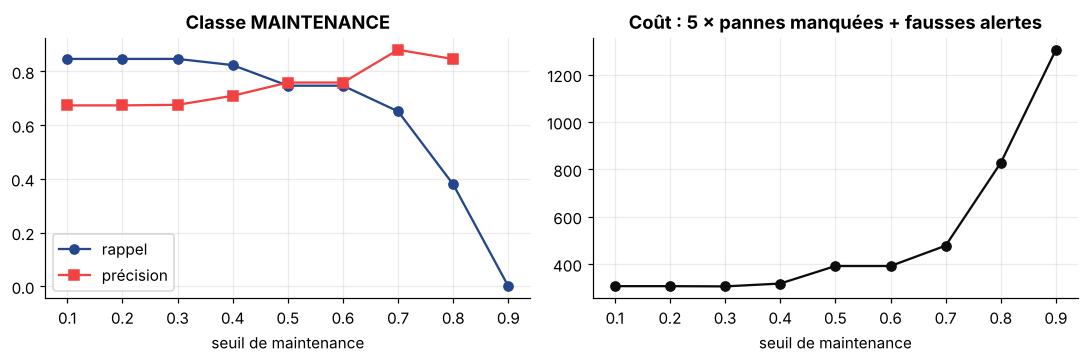

In [14]:
# Solution possible.
seuils = np.linspace(0.1, 0.9, 9)
rappels, precisions, couts = [], [], []
for s in seuils:
    pred = DecideurBayesien(reseau, seuil_maintenance=s).predire(X_test)
    manquees = np.sum((y_test == 3) & (pred != 3))
    fausses = np.sum((y_test != 3) & (pred == 3))
    rappels.append(np.mean(pred[y_test == 3] == 3))
    precisions.append(np.mean(y_test[pred == 3] == 3) if (pred == 3).any() else np.nan)
    couts.append(5 * manquees + fausses)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(seuils, rappels, "o-", color=BLEU, label="rappel")
axes[0].plot(seuils, precisions, "s-", color=ROUGE, label="précision")
axes[0].set(xlabel="seuil de maintenance", title="Classe MAINTENANCE")
axes[0].legend()
axes[1].plot(seuils, couts, "o-", color=NOIR)
axes[1].set(xlabel="seuil de maintenance", title="Coût : 5 × pannes manquées + fausses alertes")
plt.tight_layout()
print(f"Seuil de coût minimal : {seuils[int(np.argmin(couts))]:.1f}")

**Lecture.** Les évidences étant binaires, la probabilité a posteriori ne prend que quelques valeurs : la courbe évolue par paliers. Le seuil devient un paramètre métier explicite, ce que les règles ne permettent pas.

## 4. Apprentissage supervisé

Ici, personne n'écrit de règle ni de table de probabilités : un modèle apprend la correspondance entre mesures et décision à partir d'exemples étiquetés. Nous entraînons un petit perceptron multicouche avec PyTorch. C'est la seule des trois approches où le GPU intervient (calcul tensoriel de l'entraînement et de l'inférence par lots). Sur un modèle aussi petit, le gain reste faible, voire nul.

Entraînement sur cpu en 1.22 s
Exactitude sur le jeu de test : 81.0%


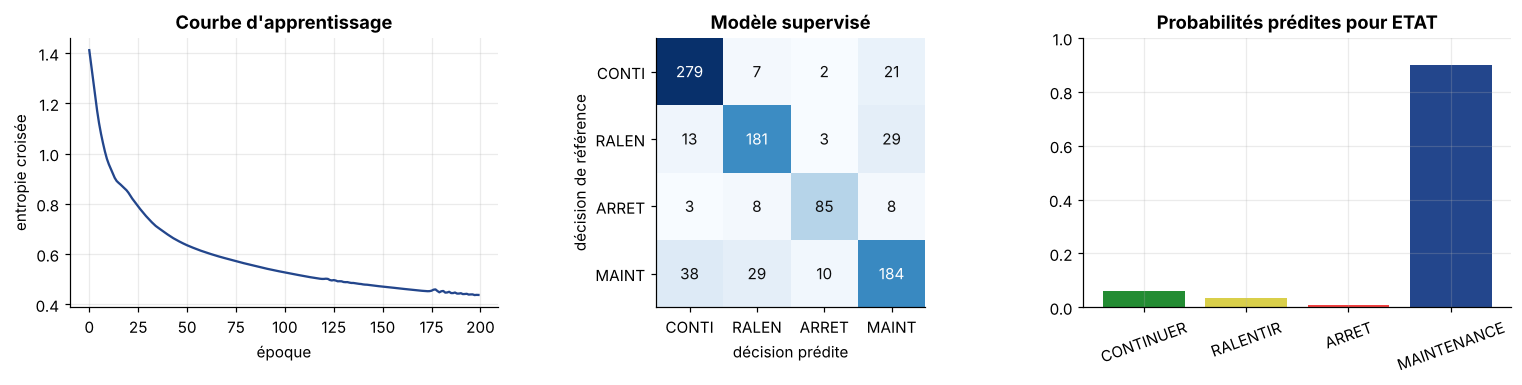

In [15]:
PARAMETRES_MLP = {
    "epoques": 200,
    "neurones_caches": 32,
    "taux_apprentissage": 0.01,
    "n_exemples": len(X_app),     # réduire pour observer le besoin en données
}


def entrainer(X_app, y_app, parametres, appareil=APPAREIL, graine=4130):
    """Entraîne un perceptron à deux couches cachées. Retourne (fonction de prédiction, pertes)."""
    torch.manual_seed(graine)
    n = parametres["n_exemples"]
    Xt = torch.tensor(X_app[:n], dtype=torch.float32, device=appareil)
    yt = torch.tensor(y_app[:n], dtype=torch.long, device=appareil)
    moyenne, ecart = Xt.mean(0), Xt.std(0).clamp(min=1e-6)     # normalisation apprise sur l'entraînement
    c = parametres["neurones_caches"]
    modele = nn.Sequential(nn.Linear(Xt.shape[1], c), nn.ReLU(), nn.Linear(c, c), nn.ReLU(), nn.Linear(c, len(DECISIONS))).to(appareil)
    optimiseur = torch.optim.Adam(modele.parameters(), lr=parametres["taux_apprentissage"])
    critere = nn.CrossEntropyLoss()
    pertes = []
    for _ in range(parametres["epoques"]):
        optimiseur.zero_grad()
        perte = critere(modele((Xt - moyenne) / ecart), yt)
        perte.backward()
        optimiseur.step()
        pertes.append(perte.item())

    def probabilites(X):
        with torch.no_grad():
            Xn = (torch.tensor(np.atleast_2d(X), dtype=torch.float32, device=appareil) - moyenne) / ecart
            return torch.softmax(modele(Xn), dim=1).cpu().numpy()

    return probabilites, pertes


debut = time.perf_counter()
proba_mlp, pertes = entrainer(X_app, y_app, PARAMETRES_MLP)
print(f"Entraînement sur {APPAREIL} en {time.perf_counter() - debut:.2f} s")
pred_mlp = proba_mlp(X_test).argmax(1)
print(f"Exactitude sur le jeu de test : {exactitude(y_test, pred_mlp):.1%}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(pertes, color=BLEU)
axes[0].set(xlabel="époque", ylabel="entropie croisée", title="Courbe d'apprentissage")
tracer_confusion(y_test, pred_mlp, "Modèle supervisé", axes[1])
p = proba_mlp(np.array([list(ETAT.values())]))[0]
axes[2].bar(DECISIONS, p, color=[COULEURS_DECISION[d] for d in DECISIONS])
axes[2].set(title="Probabilités prédites pour ETAT", ylim=(0, 1))
axes[2].tick_params(axis="x", labelrotation=20)
plt.tight_layout()

Le modèle donne des probabilités par décision, mais pas de raison : on ne sait pas quelle mesure a pesé. C'est le prix de l'apprentissage automatique des frontières.

### Exercice 3 : le besoin en données

Entraînez le modèle avec 50, 100, 200, 500, 1000 puis tous les exemples, et tracez l'exactitude en test. Le modèle rejoint-il les règles, qui n'ont besoin d'aucun exemple ? Gardez en tête que ces règles ont été écrites par un expert qui connaît les bons seuils, une situation favorable.

In [16]:
# À COMPLÉTER : remplacez la liste par vos tailles et observez.
for n in [100, 1000]:
    f, _ = entrainer(X_app, y_app, {**PARAMETRES_MLP, "n_exemples": n})
    print(n, "exemples :", f"{exactitude(y_test, f(X_test).argmax(1)):.1%}")

100 exemples : 65.3%


1000 exemples : 78.0%


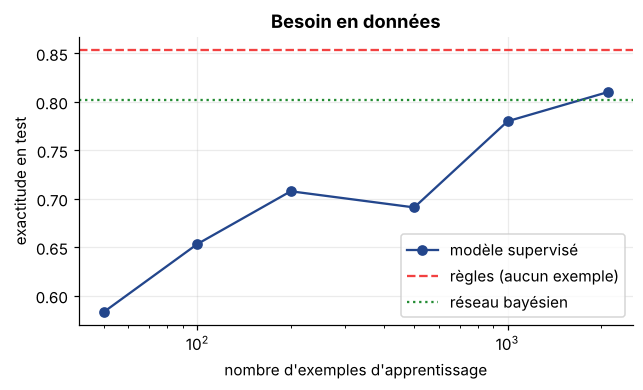

In [17]:
# Solution possible.
tailles = [50, 100, 200, 500, 1000, len(X_app)]
scores = []
for n in tailles:
    f, _ = entrainer(X_app, y_app, {**PARAMETRES_MLP, "n_exemples": n})
    scores.append(exactitude(y_test, f(X_test).argmax(1)))
plt.figure(figsize=(6.5, 3.4))
plt.semilogx(tailles, scores, "o-", color=BLEU, label="modèle supervisé")
plt.axhline(exactitude(y_test, pred_regles), color=ROUGE, ls="--", label="règles (aucun exemple)")
plt.axhline(exactitude(y_test, pred_bayes), color=VERT, ls=":", label="réseau bayésien")
plt.xlabel("nombre d'exemples d'apprentissage")
plt.ylabel("exactitude en test")
plt.title("Besoin en données")
plt.legend();

## 5. Comparaison des trois approches

### 5.1 Sur les données habituelles

In [18]:
resultats = pd.DataFrame(
    {
        "exactitude": [exactitude(y_test, p) for p in (pred_regles, pred_bayes, pred_mlp)],
        "rappel MAINTENANCE": [np.mean(p[y_test == 3] == 3) for p in (pred_regles, pred_bayes, pred_mlp)],
        "rappel ARRET": [np.mean(p[y_test == 2] == 2) for p in (pred_regles, pred_bayes, pred_mlp)],
    },
    index=["règles", "réseau bayésien", "supervisé"],
).round(3)
resultats

,exactitude,rappel MAINTENANCE,rappel ARRET
règles,0.853,0.651,0.933
réseau bayésien,0.802,0.747,0.933
supervisé,0.810,0.705,0.817


### 5.2 Hors distribution : un cas jamais vu

L'entrepôt reçoit un nouveau robot dont le moteur chauffe davantage en fonctionnement normal (+12 °C) sans être usé. Les données d'entraînement ne contiennent rien de tel. Les seuils d'arrêt de sécurité restent valables. Comment chaque approche réagit-elle ?

règles           : 85.3% puis 86.4%
réseau bayésien  : 80.2% puis 64.7%
supervisé        : 81.0% puis 72.2%


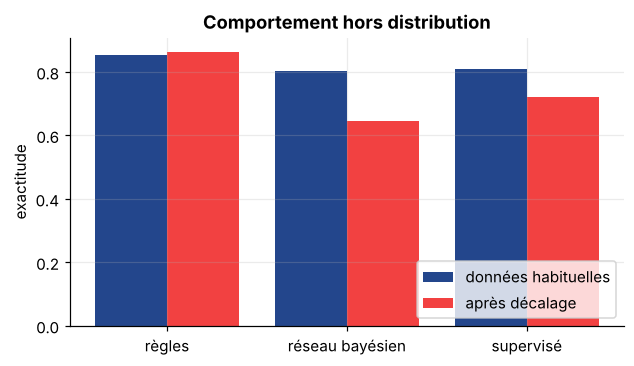

In [19]:
DECALAGE = {"temperature": 12.0}     # à modifier : {"vibration": 1.0}, {"bruit_capteur": 0.3}...

X_decale = X_test.copy()
for nom, delta in DECALAGE.items():
    X_decale[:, NOMS_VARIABLES.index(nom)] += delta
# La décision de référence ne change que pour l'arrêt de sécurité (température > 85 °C).
y_decale = y_test.copy()
y_decale[X_decale[:, 1] > SEUILS["temperature_arret"]] = 2

avant = [exactitude(y_test, p) for p in (pred_regles, pred_bayes, pred_mlp)]
apres = [exactitude(y_decale, p) for p in (predire_regles(X_decale), bayes.predire(X_decale), proba_mlp(X_decale).argmax(1))]
x = np.arange(3)
plt.figure(figsize=(6.5, 3.4))
plt.bar(x - 0.2, avant, 0.4, color=BLEU, label="données habituelles")
plt.bar(x + 0.2, apres, 0.4, color=ROUGE, label="après décalage")
plt.xticks(x, ["règles", "réseau bayésien", "supervisé"])
plt.ylabel("exactitude")
plt.title("Comportement hors distribution")
plt.legend(loc="lower right")
for nom, a, b in zip(["règles", "réseau bayésien", "supervisé"], avant, apres):
    print(f"{nom:16s} : {a:.1%} puis {b:.1%}")

**Lecture.** Avec ce décalage de température, les règles résistent, car la température n'y intervient qu'en conjonction avec d'autres mesures ou pour l'arrêt de sécurité. Le réseau bayésien interprète la chaleur comme un symptôme d'usure et multiplie les fausses alertes : il se corrige en révisant un seuil de discrétisation ou une table que l'on sait désigner. Le modèle supervisé doit être réentraîné avec des exemples du nouveau robot, et rien ne signale qu'il sort de son domaine de validité. Le classement dépend du décalage : essayez `{"vibration": 1.0}`.

### 5.3 Grille de comparaison

| Critère | Règles | Réseau bayésien | Apprentissage supervisé |
|---|---|---|---|
| Source du savoir | Expert | Expert (structure) et données (tables) | Données étiquetées |
| Explicabilité | Règle citée | Probabilités des causes | Faible sans outil dédié |
| Gestion de l'incertitude | Aucune (seuils nets) | Native | Scores, pas toujours calibrés |
| Besoin en données | Aucun | Faible à moyen | Élevé |
| Mesure manquante | Règle muette | Inférence possible quand même | Entrée à imputer |
| Maintenance | Ajout de règles, risque de conflits | Révision des tables | Réentraînement |
| Usage du GPU | Aucun | Aucun à cette échelle | Entraînement et inférence |

### Exercice 4 (TP du syllabus) : identifier la solution adaptée à un problème donné

Pour chacun des trois problèmes ci-dessous, choisissez une approche (ou une combinaison) et justifiez en une phrase au regard de la grille.

1. Arrêt d'urgence du robot quand une personne entre dans la zone : exigence réglementaire, preuve de comportement demandée.
2. Tri de colis par reconnaissance d'image, avec 200 000 photos étiquetées disponibles.
3. Diagnostic de panne d'un convoyeur neuf : aucun historique, mais un manuel constructeur décrivant causes et symptômes.

Complétez le dictionnaire puis comparez avec la proposition de la cellule suivante.

In [20]:
# À COMPLÉTER.
mes_choix = {
    "arret_urgence": ("règles", "justification..."),
    "tri_colis": ("...", "..."),
    "diagnostic_convoyeur": ("...", "..."),
}
pd.DataFrame(mes_choix, index=["approche", "justification"]).T

,approche,justification
arret_urgence,règles,justification...
tri_colis,...,...
diagnostic_convoyeur,...,...


In [21]:
# Proposition de réponse (d'autres choix argumentés sont recevables).
proposition = {
    "arret_urgence": ("règles", "Comportement vérifiable et auditable, aucune donnée nécessaire, décision immédiate."),
    "tri_colis": ("supervisé", "Signal de grande dimension, impossible à décrire par règles, données abondantes."),
    "diagnostic_convoyeur": ("réseau bayésien", "Savoir causal disponible, pas de données, incertitude sur les causes."),
}
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(proposition, index=["approche", "justification"]).T

,approche,justification
arret_urgence,règles,"Comportement vérifiable et auditable, aucune donnée nécessaire, décision immédiate."
tri_colis,supervisé,"Signal de grande dimension, impossible à décrire par règles, données abondantes."
diagnostic_convoyeur,réseau bayésien,"Savoir causal disponible, pas de données, incertitude sur les causes."


## 6. Étude de cas : diagnostic médical

Un test de dépistage a une sensibilité de 95 % (il détecte 95 % des malades) et une spécificité de 90 % (il innocente 90 % des non malades). Un patient est positif : quelle est la probabilité qu'il soit malade ? Le théorème de Bayes donne :

P(malade | positif) = sensibilité × prévalence / (sensibilité × prévalence + (1 − spécificité) × (1 − prévalence))

La réponse dépend fortement de la **prévalence**, la fréquence de la maladie dans la population testée. Les données ci-dessous sont entièrement synthétiques.

test positif  False  True 
malade                    
False         88973  10058
True             54    915

Part de malades parmi les positifs (simulation) : 8.3%
Théorème de Bayes                               : 8.8%


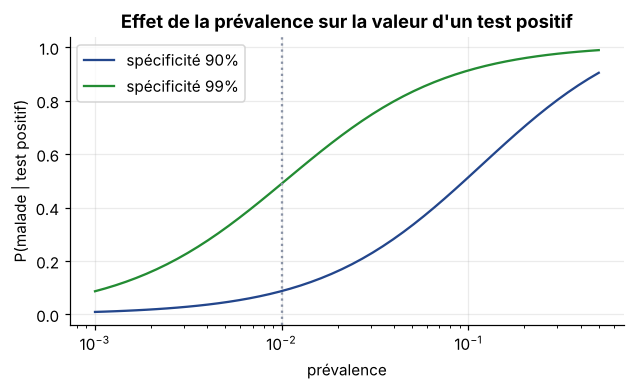

In [22]:
PARAMETRES_MEDICAL = {"prevalence": 0.01, "sensibilite": 0.95, "specificite": 0.90, "population": 100_000}

pm = PARAMETRES_MEDICAL
population = generer_diagnostic_medical(pm["population"], pm["prevalence"], pm["sensibilite"], pm["specificite"])
malade, positif = population["malade"], population["test_positif"]
print(pd.crosstab(pd.Series(malade, name="malade"), pd.Series(positif, name="test positif")))
print(f"\nPart de malades parmi les positifs (simulation) : {malade[positif].mean():.1%}")
print(f"Théorème de Bayes                               : {valeur_predictive_positive(pm['prevalence'], pm['sensibilite'], pm['specificite']):.1%}")

prevalences = np.logspace(-3, np.log10(0.5), 50)
plt.figure(figsize=(6.5, 3.4))
for sp, couleur in [(0.90, BLEU), (0.99, VERT)]:
    plt.semilogx(prevalences, [valeur_predictive_positive(p, pm["sensibilite"], sp) for p in prevalences], color=couleur, label=f"spécificité {sp:.0%}")
plt.axvline(pm["prevalence"], color=GRIS, ls=":")
plt.xlabel("prévalence")
plt.ylabel("P(malade | test positif)")
plt.title("Effet de la prévalence sur la valeur d'un test positif")
plt.legend();

**Lecture.** Avec 1 % de prévalence, moins d'un positif sur dix est réellement malade : les faux positifs, issus de la très grande population saine, dominent. Un système à règles du type « test positif donc malade » se tromperait neuf fois sur dix. Le raisonnement vaut à l'identique pour une alerte de panne rare sur un robot.

### Exercice 5 : deux tests successifs

Le patient positif passe un second test, indépendant du premier, de mêmes caractéristiques, et il est de nouveau positif. Calculez la nouvelle probabilité en réutilisant `valeur_predictive_positive` : la probabilité obtenue après le premier test devient la prévalence du second.

In [23]:
# À COMPLÉTER.
p1 = valeur_predictive_positive(0.01, 0.95, 0.90)
p2 = p1   # remplacer par le calcul après le second test
print(f"Après un test : {p1:.1%}, après deux tests : {p2:.1%}")

Après un test : 8.8%, après deux tests : 8.8%


In [24]:
# Solution possible : la mise à jour bayésienne s'enchaîne.
p = 0.01
for k in range(1, 4):
    p = valeur_predictive_positive(p, 0.95, 0.90)
    print(f"Après {k} test(s) positif(s) : {p:.1%}")

Après 1 test(s) positif(s) : 8.8%
Après 2 test(s) positif(s) : 47.7%
Après 3 test(s) positif(s) : 89.6%


## 7. Étude de cas : système de recommandation

Un système de recommandation décide quel article proposer à quel utilisateur. Nous comparons deux solutions sur une matrice de notes synthétique (200 utilisateurs, 60 articles, 25 % de notes connues) :

- **popularité** : prédire pour chaque article sa note moyenne, identique pour tous (une règle simple) ;
- **factorisation de matrice** : apprendre un vecteur de goûts par utilisateur et un vecteur de profil par article, la note prédite étant leur produit scalaire (apprentissage, entraîné avec PyTorch sur `APPAREIL`).

Erreur en test, popularité    : 1.218
Erreur en test, factorisation : 0.647


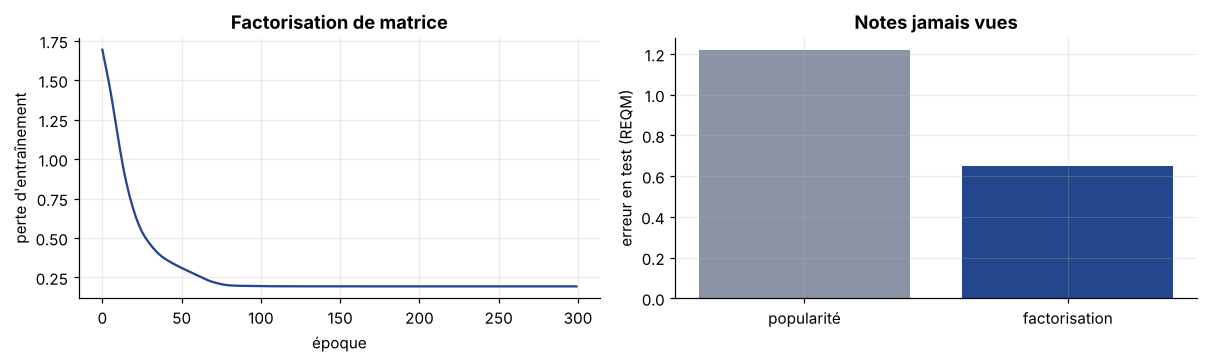

In [25]:
PARAMETRES_RECO = {"dimension": 3, "epoques": 300, "taux": 0.05, "regularisation": 0.02}

jeu = generer_notes(200, 60, graine=4130)
notes, app, test = jeu["notes"], jeu["entrainement"], jeu["test"]
moyenne_globale = np.nanmean(np.where(app, notes, np.nan))

# Solution 1 : popularité (moyenne par article sur les notes d'entraînement).
somme = np.where(app, notes, 0).sum(0)
compte = app.sum(0)
moyenne_article = np.where(compte > 0, somme / np.maximum(compte, 1), moyenne_globale)
pred_pop = np.tile(moyenne_article, (notes.shape[0], 1))


def reqm(pred, masque):
    """Racine de l'erreur quadratique moyenne sur les notes du masque."""
    return float(np.sqrt(np.mean((pred[masque] - notes[masque]) ** 2)))


def factoriser(parametres, appareil=APPAREIL, graine=4130):
    torch.manual_seed(graine)
    R = torch.tensor(np.nan_to_num(notes), dtype=torch.float32, device=appareil)
    M = torch.tensor(app, device=appareil)
    U = (0.1 * torch.randn(notes.shape[0], parametres["dimension"], device=appareil)).requires_grad_()
    V = (0.1 * torch.randn(notes.shape[1], parametres["dimension"], device=appareil)).requires_grad_()
    biais = torch.zeros(notes.shape[1], device=appareil, requires_grad=True)
    optimiseur = torch.optim.Adam([U, V, biais], lr=parametres["taux"])
    courbe = []
    for _ in range(parametres["epoques"]):
        optimiseur.zero_grad()
        pred = moyenne_globale + U @ V.T + biais
        perte = ((pred - R)[M] ** 2).mean() + parametres["regularisation"] * (U.pow(2).mean() + V.pow(2).mean())
        perte.backward()
        optimiseur.step()
        courbe.append(perte.item())
    return (moyenne_globale + U @ V.T + biais).detach().cpu().numpy(), courbe


pred_fm, courbe = factoriser(PARAMETRES_RECO)
print(f"Erreur en test, popularité    : {reqm(pred_pop, test):.3f}")
print(f"Erreur en test, factorisation : {reqm(pred_fm, test):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(courbe, color=BLEU)
axes[0].set(xlabel="époque", ylabel="perte d'entraînement", title="Factorisation de matrice")
axes[1].bar(["popularité", "factorisation"], [reqm(pred_pop, test), reqm(pred_fm, test)], color=[GRIS, BLEU])
axes[1].set(ylabel="erreur en test (REQM)", title="Notes jamais vues")
plt.tight_layout()

La factorisation personnalise : deux utilisateurs reçoivent des prédictions différentes pour le même article. La popularité garde un avantage pour un nouvel utilisateur sans aucune note (le démarrage à froid), d'où les systèmes mixtes en pratique.

### Exercice 6 : dimension latente et surapprentissage

Faites varier `dimension` (1, 2, 3, 5, 10, 20) et comparez l'erreur d'entraînement et l'erreur de test. Que se passe-t-il quand la dimension dépasse la complexité réelle des goûts (3 dans ce jeu synthétique) ?

In [26]:
# À COMPLÉTER.
for d in [1, 3]:
    p, _ = factoriser({**PARAMETRES_RECO, "dimension": d})
    print(f"dimension {d} : entraînement {reqm(p, app):.3f}, test {reqm(p, test):.3f}")

dimension 1 : entraînement 0.904, test 1.054


dimension 3 : entraînement 0.407, test 0.647


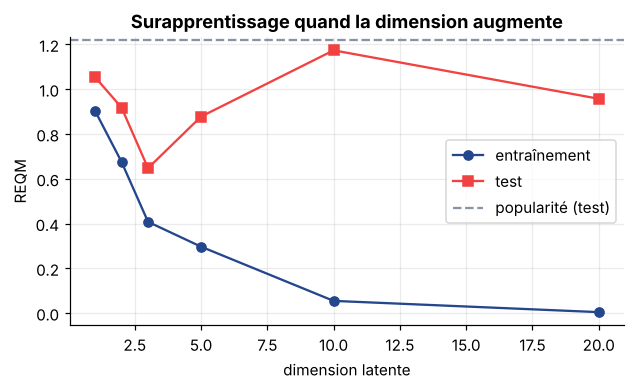

In [27]:
# Solution possible.
dimensions = [1, 2, 3, 5, 10, 20]
e_app, e_test = [], []
for d in dimensions:
    p, _ = factoriser({**PARAMETRES_RECO, "dimension": d})
    e_app.append(reqm(p, app))
    e_test.append(reqm(p, test))
plt.figure(figsize=(6.5, 3.4))
plt.plot(dimensions, e_app, "o-", color=BLEU, label="entraînement")
plt.plot(dimensions, e_test, "s-", color=ROUGE, label="test")
plt.axhline(reqm(pred_pop, test), color=GRIS, ls="--", label="popularité (test)")
plt.xlabel("dimension latente")
plt.ylabel("REQM")
plt.title("Surapprentissage quand la dimension augmente")
plt.legend();

## Synthèse du module

- Les règles offrent une décision vérifiable et immédiate, sans données, mais leurs seuils nets ignorent l'incertitude.
- Le réseau bayésien estime les causes cachées à partir d'un savoir causal et rend le compromis de décision réglable par un seuil explicite.
- L'apprentissage supervisé découvre seul les frontières, à condition de disposer d'exemples en quantité suffisante, et se dégrade sans avertir hors de son domaine d'entraînement.
- Une alerte portant sur un événement rare produit surtout des faux positifs : la prévalence compte autant que la qualité du test.
- Le GPU ne sert qu'aux calculs tensoriels (entraînement, inférence par lots). Les règles et l'inférence par énumération restent sur CPU.